# 02 - Modelleme ve Değerlendirme
Decision Tree ve Random Forest modelleri, çoğunluk sınıfı tahmini yapan bir baseline ile
karşılaştırılır.

**Yöntem:**
1. Ön işleme + model tek bir `Pipeline` içinde → veri sızıntısı yok.
2. `RandomizedSearchCV` ile hiperparametre araması (yalnızca eğitim seti, F1 skoru).
3. En iyi modelin 5-katlı çapraz doğrulaması (ortalama ± std).
4. Kapalı test setinde son değerlendirme.

> Süre: varsayılan ayarlarla birkaç dakika. Hızlı deneme için `SEARCH_ITER` ortam değişkeni düşürülebilir (bkz. `src/config.py`).

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from src import config as C
from src import data_loader, evaluation, models
from src import visualization as viz
from src.preprocessing import split_xy

viz.set_style()
pd.set_option("display.max_columns", 30)

In [2]:
train, test = data_loader.load_data()
X_train, y_train = split_xy(train)
X_test, y_test = split_xy(test)
X_train.shape, X_test.shape

((103904, 22), (25976, 22))

## 1. Baseline
Her zaman çoğunluk sınıfını tahmin eden model. Bunu geçemeyen bir model işe yaramaz.

In [3]:
fitted = {"Baseline (çoğunluk)": models.baseline(X_train, y_train)}

## 2. Hiperparametre araması ve çapraz doğrulama

In [4]:
cv_rows = []
for name in ("Decision Tree", "Random Forest"):
    search = models.tune(name, X_train, y_train, verbose=0)
    print(
        name,
        "->",
        {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        f"({search.fit_seconds_:.0f} sn)",
    )
    rep = models.cv_report(search.best_estimator_, X_train, y_train)
    rep["model"] = name
    cv_rows.append(rep)
    fitted[name] = search.best_estimator_
    joblib.dump(search.best_estimator_, C.MODEL_DIR / f"{name.replace(' ', '_').lower()}.joblib")
cv_df = pd.DataFrame(cv_rows).set_index("model")
cv_df[[c for c in cv_df.columns if c.startswith(("cv_", "train_f1"))]].round(4).T

Decision Tree -> {'min_samples_split': 50, 'min_samples_leaf': 5, 'max_depth': 20, 'criterion': 'entropy'} (6 sn)


Random Forest -> {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20} (80 sn)


model,Decision Tree,Random Forest
cv_accuracy_mean,0.9527,0.9641
cv_accuracy_std,0.0017,0.0009
cv_precision_mean,0.9551,0.9754
cv_precision_std,0.0029,0.0010
cv_recall_mean,0.9349,0.9410
cv_recall_std,0.0028,0.0022
cv_f1_mean,0.9449,0.9579
cv_f1_std,0.0020,0.0011
train_f1_mean,0.9580,0.9948
cv_roc_auc_mean,0.9878,0.9948


## 3. Aşırı öğrenme analizi
Ağaç derinleştikçe eğitim doğruluğu 1'e gider, doğrulama doğruluğu ise bir noktadan sonra düşer. Bu, bias-variance dengesinin görsel kanıtıdır.

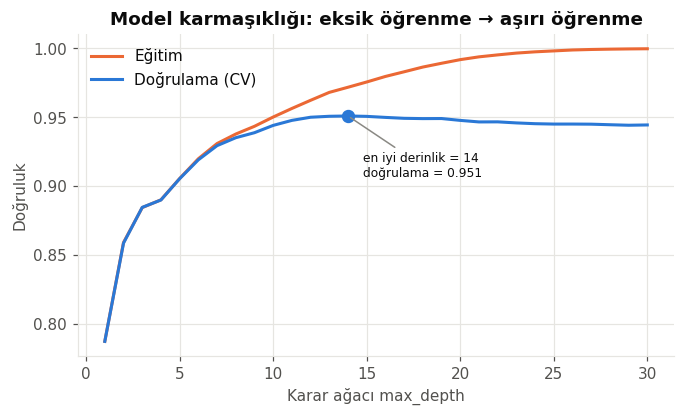

In [5]:
curve = models.depth_curve(X_train, y_train)
evaluation.plot_depth_curve(curve)
plt.show()

## 4. Test seti sonuçları

In [6]:
test_df = pd.DataFrame([evaluation.test_metrics(n, p, X_test, y_test) for n, p in fitted.items()])
test_df.round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Baseline (çoğunluk),0.5610,0.0000,0.0000,0.0000,0.5000
1,Decision Tree,0.9543,0.9548,0.9404,0.9475,0.9882
2,Random Forest,0.9647,0.9749,0.9440,0.9592,0.9948


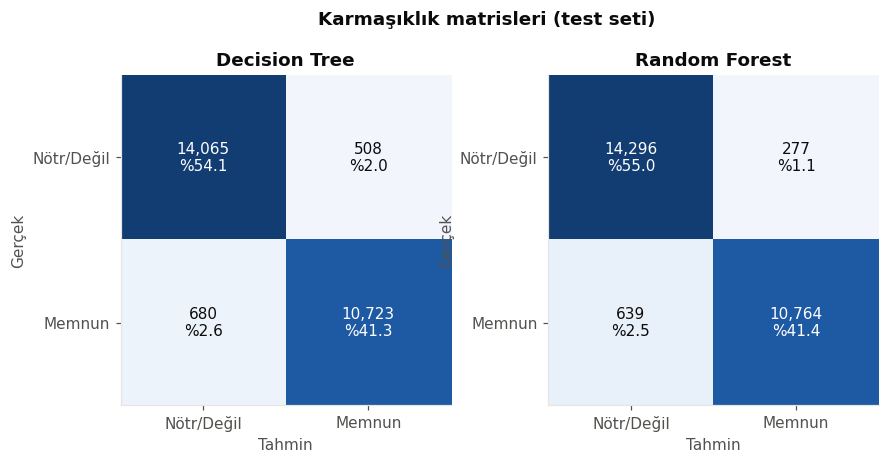

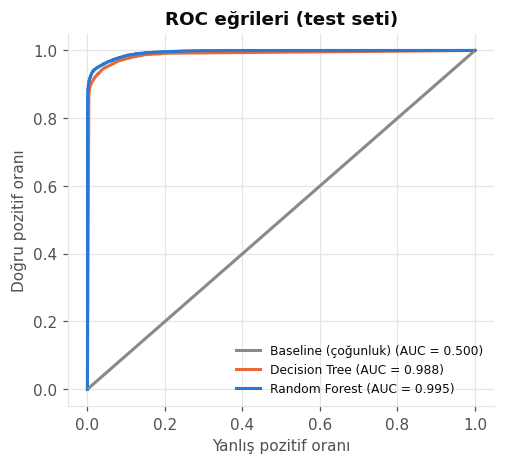

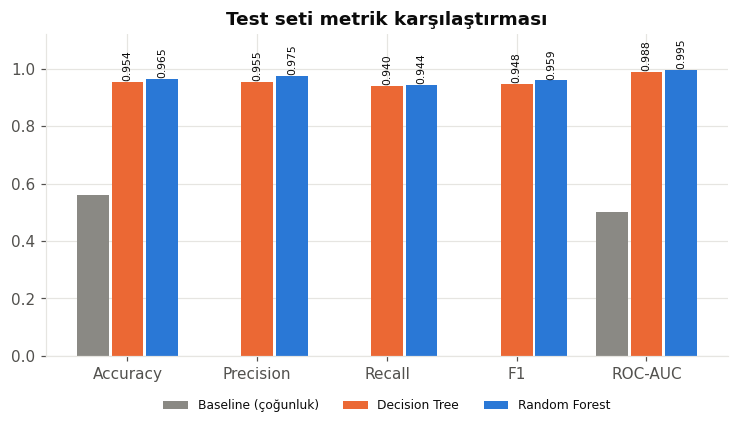

In [7]:
trained = {k: v for k, v in fitted.items() if "Baseline" not in k}
evaluation.plot_confusion(trained, X_test, y_test)
plt.show()
evaluation.plot_roc(fitted, X_test, y_test)
plt.show()
evaluation.plot_metric_comparison(test_df)
plt.show()

## 5. Karar ağacının kuralları
Tek ağacın en büyük avantajı: kararlar okunabilir kurallardır.

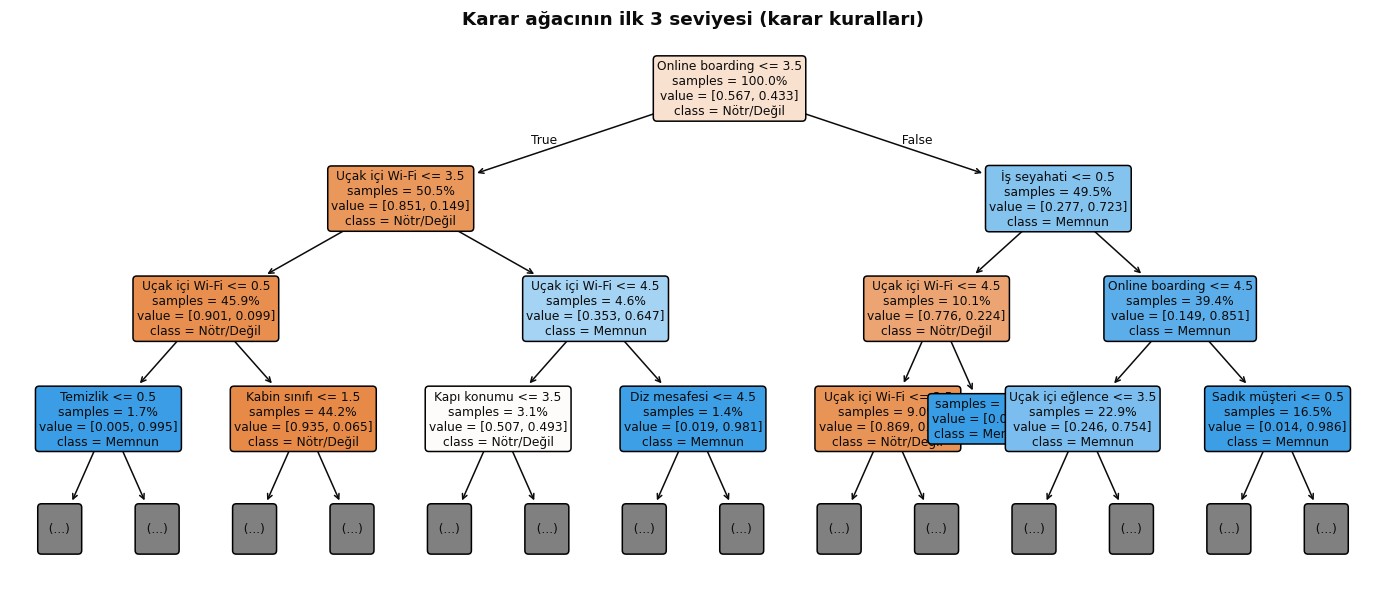

In [8]:
evaluation.plot_tree_top(fitted["Decision Tree"])
plt.show()

## 6. Literatür karşılaştırması
Aynı veri setini kullanan hakemli çalışmalarla karşılaştırma.

In [9]:
evaluation.literature_table(test_df)

,study,methods,best,accuracy
0,"Javadi, Ergin & Yüksel (2026), J. Turkish Oper...","LR, DT, RF, SVM, KNN",RF,0.9461
1,"Fadri vd. (2025), IJATIS","KNN, NB, DT, RF, SVM",RF,0.9578
2,"Zhang (2024), EMITI - SciTePress","LR, RF, AdaBoost, XGBoost + SHAP",XGBoost,0.9510
3,"Xue (2025), IAMPA - SciTePress","PCA + LR, RF",RF,0.9200
4,"Hong vd., DAAM (UMP)","KNN, DT, LR, RF, NB, AdaBoost",RF,0.8920
5,Bu çalışma - Decision Tree,"DT, RF + SHAP",Decision Tree,0.9543
6,Bu çalışma - Random Forest,"DT, RF + SHAP",Random Forest,0.9647


## Yorum
- Baseline test doğruluğu %56,10; iki model de bunu açık farkla geçiyor (DT %95,43, RF %96,47).
- RF tüm metriklerde DT'den iyi: F1 0,9592 / 0,9475, ROC-AUC 0,9948 / 0,9882.
- RF'de precision (0,9749) recall'dan (0,9440) yüksek: model "memnun" demekte temkinli, hataları
  çoğunlukla memnun yolcuyu kaçırma yönünde.
- 5-katlı CV F1: DT 0,9449 ± 0,0020, RF 0,9579 ± 0,0011. Test skorları CV ile tutarlı; sonuç
  bölünmeye duyarlı değil.
- RF'nin eğitim doğruluğu 0,9955, CV doğruluğu 0,9641. Çok sayıda ağacın ortalaması varyansı
  düşürdüğü için yüksek eğitim skoru genellemeyi bozmuyor.
- Derinlik eğrisinde doğrulama doğruluğu max_depth = 14'te en yüksek (0,9511). Daha derin ağaçlarda
  eğitim doğruluğu 1'e yaklaşırken (30'da 0,9998) doğrulama 0,944–0,945'e geriliyor. Aramada seçilen
  DT (max_depth = 20) min_samples_leaf = 5 ve min_samples_split = 50 ile sınırlandığı için eğitim
  (0,9639) ile CV (0,9527) arasındaki fark küçük.
- Aynı veriyi kullanan beş çalışmanın en iyi doğrulukları %89,2–95,8 aralığında. Bölünmeler farklı
  olduğundan birebir kıyas değildir; RF sonucu (%96,47) bu bandın biraz üzerinde.